In [1]:
import numpy as np
import pandas as pd
import anndata as ad
import scipy.io
from scipy.sparse import lil_matrix

# ─────────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────────
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"

adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

gene_names = np.array(adata.var_names)
g2i = {g: i for i, g in enumerate(gene_names)}

# TFs
tf_names = np.array(
    open(f"{BASE}/tf_names.txt").read().strip().split()
)

# ─────────────────────────────────────────────
# 2. DEFINE SHARED GENE + TF SPACE
# ─────────────────────────────────────────────

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")

genes_used = sorted(set(peak_gene["gene"]) & set(gene_names))
tfs_used   = sorted(set(tf_names) & set(gene_names))  # IMPORTANT: RNA-intersected TFs only

gene_idx = np.array([g2i[g] for g in genes_used])
tf_idx   = np.array([g2i[t] for t in tfs_used])

X    = X_full[:, gene_idx]   # (cells, G)
X_TF = X_full[:, tf_idx]     # (cells, T)

G, T = X.shape[1], X_TF.shape[1]

print("X:", X.shape)
print("X_TF:", X_TF.shape)

# mappings (ONLY ONCE)
gene2i = {g: i for i, g in enumerate(genes_used)}
tf2i   = {t: i for i, t in enumerate(tfs_used)}

# ─────────────────────────────────────────────
# 3. BUILD PEAK → GENE MAP (CLEAN)
# ─────────────────────────────────────────────

peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak2i = {p: i for i, p in enumerate(peaks)}

P = len(peaks)

peak_gene_mat = lil_matrix((P, G))

for _, row in peak_gene.iterrows():
    p, g = row["peak"], row["gene"]
    if p in peak2i and g in gene2i:
        peak_gene_mat[peak2i[p], gene2i[g]] = 1

peak_gene_mat = peak_gene_mat.tocsr()

# ─────────────────────────────────────────────
# 4. OPTIONAL: GENE × TF ACCESSIBILITY MATRIX M
# ─────────────────────────────────────────────

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()

assert peak_tf.shape[0] == len(peaks)

# gene × TF motif
M_full = peak_gene_mat.T @ peak_tf   # (G, motif_TFs)
M_full = (M_full > 0).astype(np.float32)

tf2i_motif = {t: i for i, t in enumerate(tf_names)}

# align ONLY to TFs we kept
tf_cols = np.array([tf2i_motif[t] for t in tfs_used])

M = np.array(M_full[:, tf_cols].todense())

print("M:", M.shape)

# ─────────────────────────────────────────────
# 5. FINAL SANITY CHECKS
# ─────────────────────────────────────────────

assert X.shape[1] == G
assert X_TF.shape[1] == T
assert M.shape == (G, T)

print("✓ Pipeline consistent and aligned")

X: (1035, 11483)
X_TF: (1035, 277)
M: (11483, 277)
✓ Pipeline consistent and aligned


In [2]:
# ─────────────────────────────────────────────
# 5. TORCH CONVERSION (CLEAN)
# ─────────────────────────────────────────────

import torch

X_t    = torch.tensor(X, dtype=torch.float32)
X_TF_t = torch.tensor(X_TF, dtype=torch.float32)

print("Torch tensors:")
print("X_t   :", X_t.shape)
print("X_TF_t:", X_TF_t.shape)

# ─────────────────────────────────────────────
# 6. NEAREST NEIGHBORS (OPTIONAL STRUCTURE ONLY)
# ─────────────────────────────────────────────

from sklearn.neighbors import NearestNeighbors

# NOTE:
# This is ONLY for optional smoothness regularization.
# It does NOT define supervision or velocity.

nn_mdl = NearestNeighbors(n_neighbors=30)
nn_idx = nn_mdl.fit(X).kneighbors(X, return_distance=False)

nn_idx_t = torch.tensor(nn_idx, dtype=torch.long)

print("nn_idx_t:", nn_idx_t.shape)

Torch tensors:
X_t   : torch.Size([1035, 11483])
X_TF_t: torch.Size([1035, 277])
nn_idx_t: torch.Size([1035, 30])


# Load ATAC counts and gene scores for direction

In [3]:
# ─────────────────────────────────────────────
# LOAD ATAC (cells x peaks)
# ─────────────────────────────────────────────

from scipy.io import mmread
import numpy as np
import pandas as pd
from scipy.sparse import lil_matrix
from sklearn.preprocessing import normalize
from sklearn.decomposition import TruncatedSVD
import torch

print("Loading ATAC...")

atac_raw = mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.T.astype(np.float32)   # (cells, peaks)

print("atac_X:", atac_X.shape)

# ─────────────────────────────────────────────
# PEAK ANNOTATIONS
# ─────────────────────────────────────────────

peaks_df = pd.read_csv(
    f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.peaks.txt.gz",
    sep="\t"
)

peak_names = peaks_df["Feature"].tolist()

def norm_peak(p):
    # unify format with peak_gene table
    return p.replace("-", ":", 1)

peak_to_idx = {p: i for i, p in enumerate(peak_names)}

# ─────────────────────────────────────────────
# PEAK → GENE PRIOR (STATIC REGULATORY MAP)
# ─────────────────────────────────────────────

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")

gene2i = {g: i for i, g in enumerate(genes_used)}  # from earlier cleaned block

P = len(peak_names)
G = len(genes_used)

peak_gene_mat = lil_matrix((P, G))

for _, row in peak_gene.iterrows():
    p = norm_peak(row["peak"])
    g = row["gene"]

    if p in peak_to_idx and g in gene2i:
        peak_gene_mat[peak_to_idx[p], gene2i[g]] = 1

peak_gene_mat = peak_gene_mat.tocsr()

print("peak_gene_mat:", peak_gene_mat.shape)

# ─────────────────────────────────────────────
# GENE ACTIVITY (OPTIONAL DIAGNOSTIC ONLY)
# ─────────────────────────────────────────────

print("Computing gene activity (diagnostic)...")

gene_activity = atac_X @ peak_gene_mat   # (cells, genes)

gene_activity = normalize(gene_activity, norm="l1", axis=1)
gene_activity = gene_activity.toarray()

gene_activity_t = torch.tensor(gene_activity, dtype=torch.float32)

print("gene_activity:", gene_activity.shape)

# ─────────────────────────────────────────────
# ATAC LATENT FEATURES (MODEL INPUT ONLY)
# ─────────────────────────────────────────────

print("Computing ATAC LSI...")

svd = TruncatedSVD(n_components=50, random_state=42)
atac_lsi = svd.fit_transform(atac_X)

atac_t = torch.tensor(atac_lsi, dtype=torch.float32)

print("atac_t:", atac_t.shape)

Loading ATAC...
atac_X: (18489, 571389)
peak_gene_mat: (571389, 11483)
Computing gene activity (diagnostic)...
gene_activity: (18489, 11483)
Computing ATAC LSI...
atac_t: torch.Size([18489, 50])


In [1]:
from sklearn.decomposition import TruncatedSVD
import numpy as np
import torch

# ─────────────────────────────────────────────
# ATAC preprocessing (TF-IDF → LSI)
# ─────────────────────────────────────────────

print("Computing ATAC LSI...")

# library size normalization (row-wise)
lib_size = np.array(atac_X.sum(axis=1)).flatten() + 1e-8
atac_tf = atac_X.multiply(1.0 / lib_size[:, None])

# log transform
atac_tf = atac_tf.copy()
atac_tf.data = np.log1p(atac_tf.data * 1e4)

# convert to dense only for SVD
atac_tf_dense = atac_tf.toarray()

from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=50, random_state=42)
atac_lsi = svd.fit_transform(atac_tf_dense)

atac_t = torch.tensor(atac_lsi, dtype=torch.float32)

print("atac_t:", atac_t.shape)

Computing ATAC LSI...


NameError: name 'atac_X' is not defined

In [5]:
print(X_t.shape, atac_t.shape)

torch.Size([1035, 11483]) torch.Size([18489, 50])


In [20]:
class GRNVelocityModel(nn.Module):
    def __init__(self, G, T):
        super().__init__()
        self.A = nn.Parameter(torch.randn(G, T) * 0.01)
        self.alpha = 1.0

    def velocity(self, X_TF):
        return self.alpha * (X_TF @ self.A.T)

    def forward(self, X, X_TF, dt=0.1):
        V = self.velocity(X_TF)
        X_pred = X + dt * V
        return V, X_pred

In [16]:
def flow_loss(model, X, X_TF, dt=0.1,
              lambda_reg=1e-4,
              lambda_smooth=1e-2):

    V, X_pred = model(X, X_TF, dt)

    # ── 1. Self-consistency loss ─────────────────────────────
    # predicted state should not explode off data manifold
    loss_recon = F.mse_loss(X_pred, X)

    # ── 2. Velocity smoothness ───────────────────────────────
    # nearby cells (in expression space) should have similar velocity
    idx = torch.randint(0, X.shape[0], (512,))
    V_sample = V[idx]

    V_smooth = F.mse_loss(
        V_sample,
        V_sample.mean(dim=0, keepdim=True)
    )

    # ── 3. GRN sparsity (biological prior) ───────────────────
    loss_sparse = model.A.abs().mean()

    total = loss_recon + lambda_smooth * V_smooth + lambda_reg * loss_sparse

    return total, {
        "recon": loss_recon.item(),
        "smooth": V_smooth.item(),
        "sparse": loss_sparse.item()
    }

In [17]:
def train(model, X, X_TF, nn_idx, epochs=200, lr=1e-3):
    
    # FORCE correct type (prevents silent bugs)
    epochs = int(epochs)

    opt = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in trange(epochs):
        opt.zero_grad()

        loss, parts = flow_loss(model, X, X_TF)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        if epoch % 10 == 0:
            print(f"Epoch {epoch} | loss={loss.item():.4f}")

    return model

In [21]:
print("epochs type check:", type(200))
print("X shape:", X_t.shape)
print("X_TF shape:", X_TF_t.shape)

epochs type check: <class 'int'>
X shape: torch.Size([1035, 11483])
X_TF shape: torch.Size([1035, 277])


In [22]:
G = len(genes_used)
T = len(tfs_used)

model = GRNVelocityModel(G=G, T=T)

assert X_t.shape[1] == G
assert X_TF_t.shape[1] == T

model = train(model, X_t, X_TF_t, nn_idx_t)

/tmp/ipykernel_19232/2049647359.py:16: UserWarning: Using a target size (torch.Size([1, 11483])) that is different to the input size (torch.Size([512, 11483])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  V_smooth = F.mse_loss(
  0%|▎                                                                         | 1/200 [00:00<01:51,  1.78it/s]

Epoch 0 | loss=8.3357


  6%|████                                                                     | 11/200 [00:04<01:13,  2.58it/s]

Epoch 10 | loss=1.2468


 10%|███████▋                                                                 | 21/200 [00:08<01:10,  2.54it/s]

Epoch 20 | loss=0.3576


... (31 outputs left out)

Epoch 180 | loss=0.0000


 96%|████████████████████████████████████████████████████████████████████▊   | 191/200 [01:12<00:03,  2.72it/s]

Epoch 190 | loss=0.0000


100%|████████████████████████████████████████████████████████████████████████| 200/200 [01:15<00:00,  2.66it/s]


In [25]:
import numpy as np
import torch

with torch.no_grad():
    V_pred, X_pred = model(X_t, X_TF_t)
    A_learned = model.A

np.save("new_method/V_pred_learned.npy", V_pred.cpu().detach().numpy())
np.save("new_method/X_pred_learned.npy", X_pred.cpu().detach().numpy())
np.save("new_method/A_learned.npy", A_learned.cpu().detach().numpy())

np.save("new_method/gene_idx.npy", gene_idx)
np.save("new_method/tf_idx.npy", tf_idx)

np.save("new_method/gene_names.npy", genes_used)
np.save("new_method/tf_names.npy", tfs_used)

print("Saved model outputs + aligned metadata")

Saved model outputs + aligned metadata


In [18]:
%matplotlib inline  

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


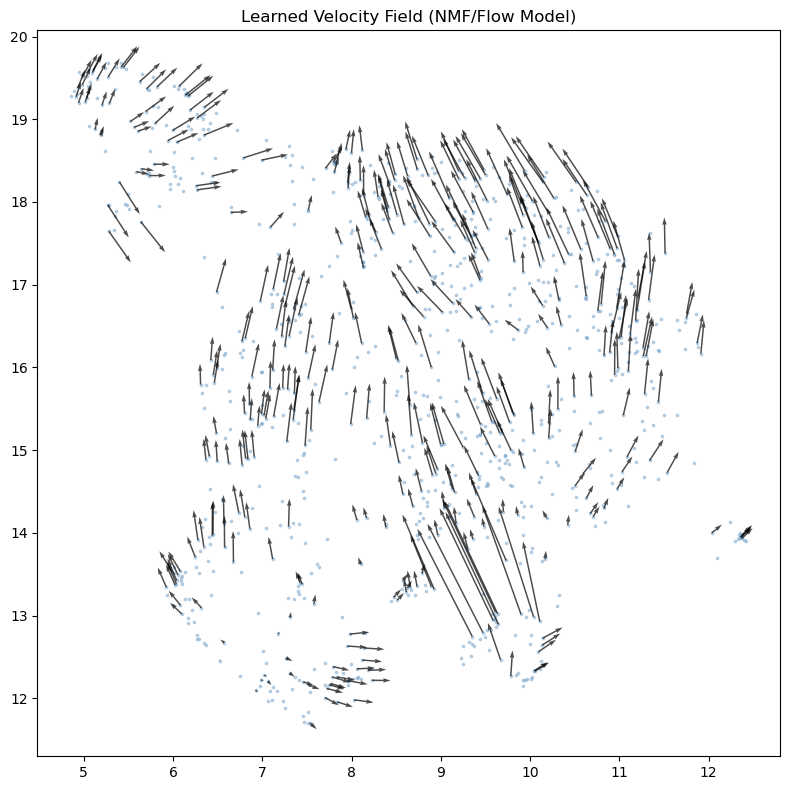

Velocity–pseudotime alignment: -0.004365103039886147


In [26]:
# visualize_velocity.py (UPDATED FOR LEARNED MODEL)

import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

# =========================
# 1. LOAD DATA
# =========================
import numpy as np
import anndata as ad

adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("new_method/V_pred_learned.npy")
gene_idx = np.load("new_method/gene_idx.npy")

# ensure same X used in training
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
X = X_full[:, gene_idx]

# =========================
# 2. SANITY CHECK (CORRECT VERSION)
# =========================
assert X.shape[0] == V_pred.shape[0], "cell mismatch"

# DO NOT assume gene alignment is automatic — check it explicitly
assert X.shape[1] == V_pred.shape[1], \
    f"gene mismatch: X={X.shape}, V={V_pred.shape}"

# =========================
# 3. UMAP EMBEDDING
# =========================
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# =========================
# 4. PROJECT VELOCITY TO UMAP
# =========================
eps = 0.5

X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# =========================
# 5. SMOOTH VELOCITY FIELD
# =========================
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# =========================
# 6. PLOT VECTOR FIELD
# =========================
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Learned Velocity Field (NMF/Flow Model)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

# =========================================================
# 7. FIXED CORRELATION (IMPORTANT — YOUR OLD ONE WAS WRONG)
# =========================================================

# WRONG BEFORE:
# spearmanr(pseudotime, dot(V, X[i+1] - X[i]))

# CORRECT IDEA:
# does velocity align with actual transitions in pseudotime ordering?

pseudo = adata.obs["facs_pseudotime"].values

# sort by pseudotime
order = np.argsort(pseudo)

X_sorted = X[order]
V_sorted = V_pred[order]

# finite differences along trajectory
dX = X_sorted[1:] - X_sorted[:-1]
V_mid = V_sorted[:-1]

# alignment score (cosine-like dot product)
alignment = np.sum(V_mid * dX, axis=1)

score = spearmanr(pseudo[order][:-1], alignment)[0]

print("Velocity–pseudotime alignment:", score)

In [27]:
# Metrics

from sklearn.metrics import r2_score
from scipy.stats import spearmanr
import scvelo as scv

# Metric A: Cross-boundary direction correctness (CBDir)
# Requires cell type labels. Measures whether velocity points from 
# progenitor clusters toward differentiated clusters.

adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

# scv.tl.velocity_graph(adata)  # uses your V_pred stored in adata.layers['velocity']
# scv.tl.velocity_confidence(adata)
# print(adata.obs['velocity_confidence'].mean())  # higher = more consistent field

# Metric B: velocity graph transition entropy
# A good velocity field should produce low-entropy transitions 
# (cells confidently point one direction, not scattered)
# scv.tl.velocity_graph(adata)
# Inspect adata.uns['velocity_graph'] — row entropy tells you confidence

# Metric C: correlation with RNA-based pseudotime (DPT) 
# as an internal consistency check separate from FACS
from scipy.stats import spearmanr
dpt_corr = spearmanr(adata.obs['dpt_pseudotime'], 
                      adata.obs['facs_pseudotime'])[0]
print("DPT-FACS agreement:", dpt_corr)  # sanity check your pseudotime labels

# Metric D: per-cell consistency (your best unsupervised metric)
# Does velocity at cell i agree with velocity at its neighbors?
def velocity_consistency(V_pred, nn_idx):
    scores = []
    for i in range(len(V_pred)):
        nbr_v = V_pred[nn_idx[i]]  # (K, G)
        v_i = V_pred[i]            # (G,)
        cos = (nbr_v @ v_i) / (
            np.linalg.norm(nbr_v, axis=1) * np.linalg.norm(v_i) + 1e-8
        )
        scores.append(cos.mean())
    return np.array(scores)

consistency = velocity_consistency(V_pred, idx)
print("Mean velocity consistency:", consistency.mean())
# This is fully unsupervised — no pseudotime needed

DPT-FACS agreement: 0.39182819939137054
Mean velocity consistency: 0.7050597


In [11]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

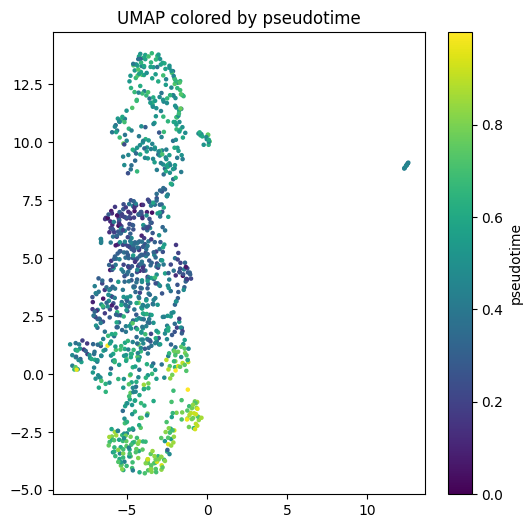

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(X_umap[:,0], X_umap[:,1], c=adata.obs["facs_pseudotime"], s=5)
plt.colorbar(label="pseudotime")
plt.title("UMAP colored by pseudotime")
plt.show()

In [28]:
from scipy.stats import spearmanr

score = spearmanr(
    adata.obs["facs_pseudotime"],
    np.linalg.norm(V_pred, axis=1)
)[0]

print(score)

0.038662553673774074


In [29]:
score = spearmanr(
    adata.obs["facs_pseudotime"],
    (V_pred * X).sum(axis=1)
)[0]
print(score)

-0.09872789170145084


In [33]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'

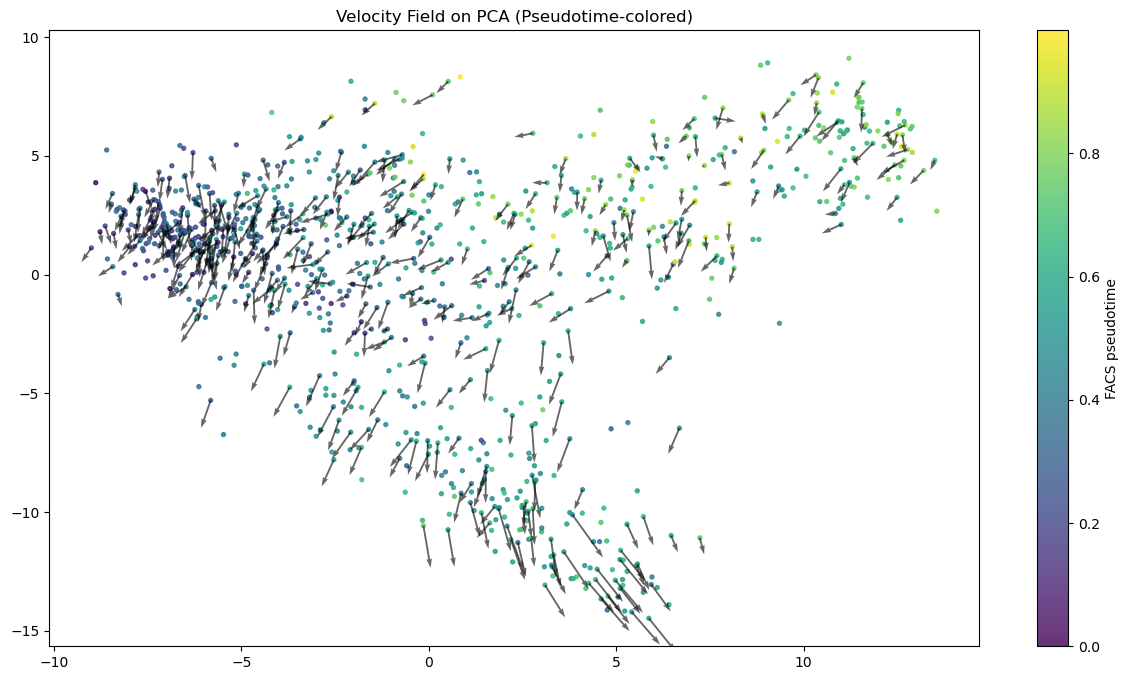

In [40]:
from sklearn.decomposition import PCA

# ─────────────────────────────────────────────
# PCA ON ALIGNED GENE SPACE (IMPORTANT)
# ─────────────────────────────────────────────

pca = PCA(n_components=10, random_state=42)

# X is already restricted to genes_used → CORRECT SPACE
pca.fit(X)

# gene loadings (G × PCs)
pca_components = pca.components_.T

# project velocity into PCA space
V_pca = V_pred @ pca_components
V_pca = -V_pca

from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=30).fit(X_pca)
_, idx = nn.kneighbors(X_pca)

V_pca_smooth = np.array([
    V_pca[idx[i]].mean(axis=0)
    for i in range(len(X_pca))
])

V_pca_smooth = V_pca_smooth / (np.linalg.norm(V_pca_smooth, axis=1, keepdims=True) + 1e-8)
V_pca_smooth *= 0.5

import numpy as np
import matplotlib.pyplot as plt

pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(15, 8))

sc = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=8,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

sample = np.random.choice(len(X_pca), 400, replace=False)

ax.quiver(
    X_pca[sample, 0], X_pca[sample, 1],
    V_pca_smooth[sample, 0], V_pca_smooth[sample, 1],
    color="black", alpha=0.6, scale=3, width=0.002
)

ax.set_title("Velocity Field on PCA (Pseudotime-colored)")
plt.show()

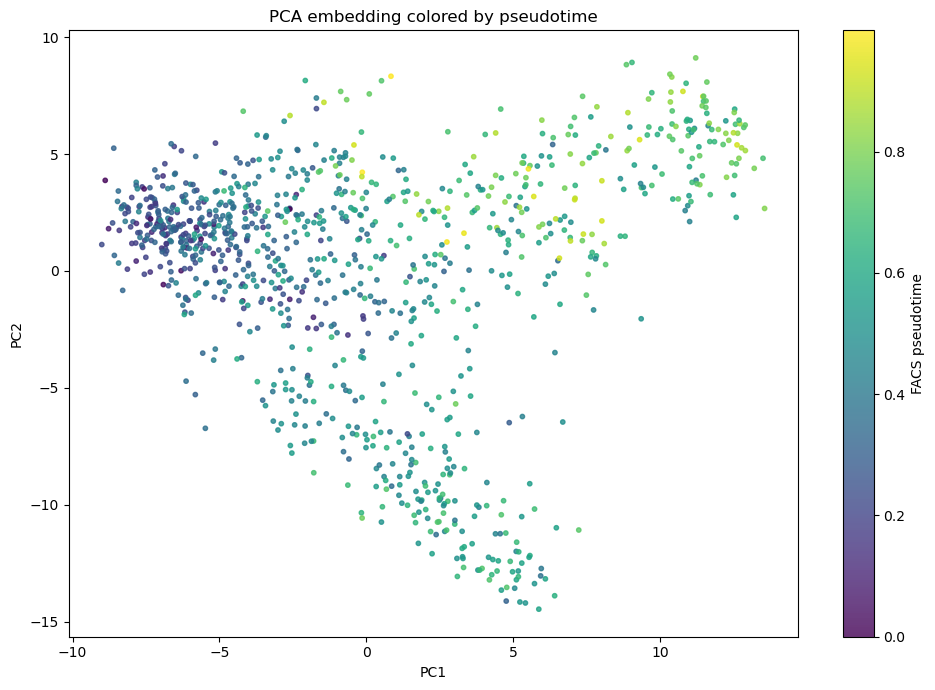

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# PCA embedding
X_pca = adata.obsm["X_pca"][:, :2]

# pseudotime (or swap for any obs label)
pseudo = adata.obs["facs_pseudotime"].values

fig, ax = plt.subplots(figsize=(10, 7))

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pseudo,
    cmap="viridis",
    s=10,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="FACS pseudotime")

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA embedding colored by pseudotime")

plt.tight_layout()
plt.show()

In [48]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'

In [49]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

N = X.shape[0]

nn = NearestNeighbors(n_neighbors=30).fit(X)
neighbors = nn.kneighbors(X, return_distance=False)

def flow_alignment(V_pred, X, neighbors):
    N = X.shape[0]
    scores = []

    for i in range(N):
        vi = V_pred[i]
        vi_norm = np.linalg.norm(vi) + 1e-8

        for j in neighbors[i]:
            dx = X[j] - X[i]

            score = np.dot(vi, dx) / (
                vi_norm * (np.linalg.norm(dx) + 1e-8)
            )
            scores.append(score)

    return np.mean(scores)

score_forward = flow_alignment(V_pred, X, neighbors)
score_backward = flow_alignment(-V_pred, X, neighbors)

print("forward:", score_forward)
print("backward:", score_backward)

forward: 0.0033853725
backward: -0.0033853725


# Compare to Cell Oracle GRN

In [41]:
A = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
A_genes = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True)
A_tfs   = np.load("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/cell_oracle_run/cell_oracle_global_A/A_tfs.npy", allow_pickle=True)

In [42]:
your_gene2i = {g: i for i, g in enumerate(genes_used)}
your_tf2i   = {t: i for i, t in enumerate(tfs_used)}

co_gene2i = {g: i for i, g in enumerate(A_genes)}  # columns
co_tf2i   = {t: i for i, t in enumerate(A_tfs)}    # rows

In [48]:
common_genes = sorted(set(genes_used) & set(A_genes))
common_tfs   = sorted(set(tfs_used) & set(A_tfs))

co_gene_idx = np.array([co_gene2i[g] for g in common_genes])
co_tf_idx   = np.array([co_tf2i[t] for t in common_tfs])

# IMPORTANT: TF first, genes second
A_co_sub = A[np.ix_(co_tf_idx, co_gene_idx)]
A_co_fixed = A_co_sub.T  # now (genes × TFs)

assert A_your_sub.shape == A_co_fixed.shape

In [49]:
print(len(common_genes))
print(len(common_tfs))

2995
277


In [50]:
from scipy.stats import spearmanr

corr = spearmanr(
    A_your_sub.flatten(),
    A_co_sub.flatten()
)[0]

print("Spearman correlation:", corr)

Spearman correlation: -0.0001911825775587419


In [51]:
k = 2000  # top edges

your_top = np.argsort(A_your_sub.flatten())[-k:]
co_top   = np.argsort(A_co_sub.flatten())[-k:]

overlap = len(set(your_top) & set(co_top)) / k
print("Top-edge overlap:", overlap)

Top-edge overlap: 0.002


In [52]:
from scipy.stats import spearmanr

tf_scores = []

for j, tf in enumerate(common_tfs):
    r = spearmanr(A_your_sub[:, j], A_co_sub[:, j])[0]
    tf_scores.append((tf, r))

tf_scores = sorted(tf_scores, key=lambda x: x[1], reverse=True)

print("Top matching TFs:")
print(tf_scores[:10])

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 2995 and the array at index 1 has size 277

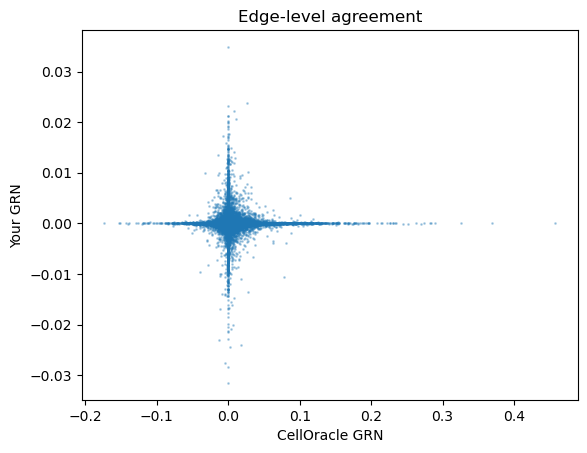

In [53]:
import matplotlib.pyplot as plt

plt.scatter(
    A_co_sub.flatten(),
    A_your_sub.flatten(),
    s=1,
    alpha=0.3
)

plt.xlabel("CellOracle GRN")
plt.ylabel("Your GRN")
plt.title("Edge-level agreement")
plt.show()